
# Deep Learning — Assignment 1
## MicroGrad: Scalar Automatic Differentiation Engine

**Objective:**

Build and demonstrate a scalar automatic differentiation engine
from scratch using Python.

This notebook demonstrates:
1. Computational graph construction.
2. Automatic differentiation and backpropagation.
3. Neural network implementation using MicroGrad.
4. Training an MLP using gradient descent.
5. Visualization of training results.


In [1]:

import random
import matplotlib.pyplot as plt

from src.engine import Value
from src.nn import MLP

# Reproducibility
random.seed(42)

print("MicroGrad imports successful!")


MicroGrad imports successful!


In [2]:

# Generate training data
xs = [[x] for x in [
    -2.0, -1.8, -1.6, -1.4, -1.2,
    -1.0, -0.8, -0.6, -0.4, -0.2,
     0.0,  0.2,  0.4,  0.6,  0.8,
     1.0,  1.2,  1.4,  1.6,  1.8,
     2.0
]]

ys = [[x[0] ** 2] for x in xs]

print("Number of samples:", len(xs))
print("First input:", xs[0])
print("First target:", ys[0])


Number of samples: 21
First input: [-2.0]
First target: [4.0]


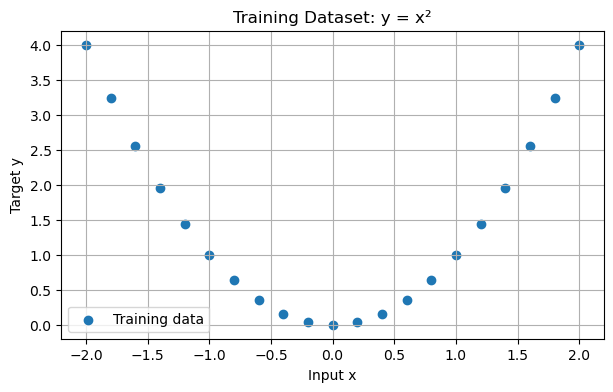

In [3]:

plt.figure(figsize=(7, 4))

plt.scatter(
    [x[0] for x in xs],
    [y[0] for y in ys],
    label="Training data"
)

plt.xlabel("Input x")
plt.ylabel("Target y")
plt.title("Training Dataset: y = x²")
plt.legend()
plt.grid(True)
plt.show()


In [4]:

# Create the neural network

model = MLP(1, [8, 8, 1])

print("Model created successfully!")
print("Number of parameters:", len(model.parameters()))


Model created successfully!
Number of parameters: 97


In [5]:

# Normalize inputs and targets

x_train = [x[0] / 2.0 for x in xs]

y_train = [y[0] / 2.0 - 1.0 for y in ys]

print("First normalized input:", x_train[0])
print("First normalized target:", y_train[0])
print("Minimum target:", min(y_train))
print("Maximum target:", max(y_train))


First normalized input: -1.0
First normalized target: 1.0
Minimum target: -1.0
Maximum target: 1.0


In [6]:

def calculate_loss(model, x_data, y_data):
    predictions = [model([x]) for x in x_data]

    loss = sum(
        [(pred - target) ** 2 for pred, target in zip(predictions, y_data)],
        Value(0.0)
    ) / len(x_data)

    return loss


In [7]:

# Training configuration

epochs = 3000
learning_rate = 0.05

loss_history = []

# Training loop
for epoch in range(epochs):

    # Reset gradients
    model.zero_grad()

    # Forward pass and loss calculation
    loss = calculate_loss(model, x_train, y_train)

    # Backpropagation
    loss.backward()

    # Gradient descent: update parameters
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    # Store loss for visualization
    loss_history.append(loss.data)

    # Display progress
    if epoch % 300 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.6f}")

print("\nTraining completed!")
print("Final loss:", loss_history[-1])


Epoch 0: Loss = 1.875045
Epoch 300: Loss = 0.013338
Epoch 600: Loss = 0.009785
Epoch 900: Loss = 0.008945
Epoch 1200: Loss = 0.008515
Epoch 1500: Loss = 0.008225
Epoch 1800: Loss = 0.007991
Epoch 2100: Loss = 0.007782
Epoch 2400: Loss = 0.007583
Epoch 2700: Loss = 0.007389

Training completed!
Final loss: 0.007194786305134074


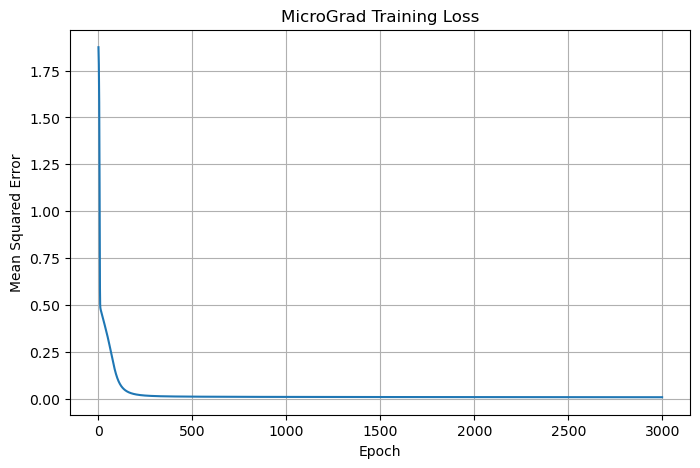

In [8]:

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("MicroGrad Training Loss")

plt.grid(True)
plt.show()


In [9]:

# Generate predictions in the original scale

predictions = []

for x in xs:
    normalized_x = x[0] / 2.0

    pred = model([normalized_x])

    original_prediction = (pred.data + 1.0) * 2.0

    predictions.append(original_prediction)

actual_values = [y[0] for y in ys]
input_values = [x[0] for x in xs]

# Display some predictions
for i in range(0, len(xs), 4):
    print(
        f"x = {input_values[i]:5.2f} | "
        f"Actual = {actual_values[i]:6.3f} | "
        f"Predicted = {predictions[i]:6.3f}"
    )


x = -2.00 | Actual =  4.000 | Predicted =  3.606
x = -1.20 | Actual =  1.440 | Predicted =  1.354
x = -0.40 | Actual =  0.160 | Predicted =  0.274
x =  0.40 | Actual =  0.160 | Predicted =  0.283
x =  1.20 | Actual =  1.440 | Predicted =  1.328
x =  2.00 | Actual =  4.000 | Predicted =  3.647


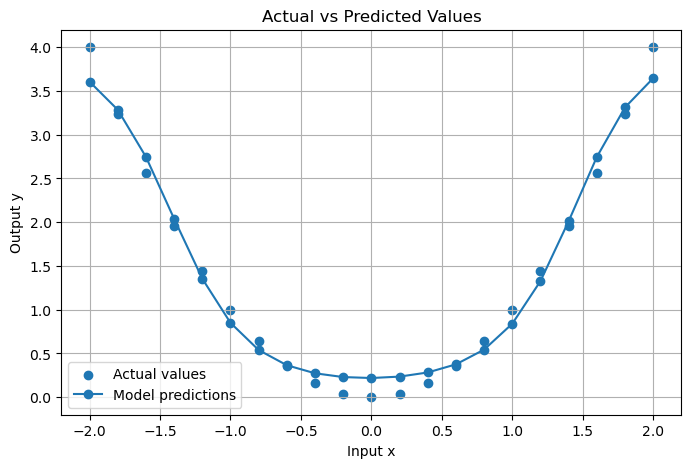

In [10]:

plt.figure(figsize=(8, 5))

plt.scatter(
    input_values,
    actual_values,
    label="Actual values"
)

plt.plot(
    input_values,
    predictions,
    label="Model predictions",
    marker="o"
)

plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.grid(True)
plt.show()



## Conclusion

In this assignment, we implemented a scalar automatic
differentiation engine called MicroGrad.

The implementation included:

1. Value objects and computational graph construction.
2. Mathematical operators and their local derivatives.
3. Tanh and exponential activation functions.
4. Topological sorting using Depth-First Search.
5. Backpropagation using the chain rule.
6. Neural network components: Neuron, Layer, and MLP.

We then used our implementation to train a multilayer
perceptron using gradient descent.

The experiment demonstrated how gradients are calculated
and used to update network parameters to minimize loss.

The final predictions were compared with the actual
quadratic function values.
